<div style="background: linear-gradient(120deg, #1a3a5c 0%, #2d6a9f 60%, #4a9eda 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);">
    <img src='Figures/iteso.jpg' style='height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0;'/>
    <div style='border-left: 2px solid rgba(255,255,255,0.4); padding-left: 28px;'>
        <h1 style='margin: 0 0 8px 0; color: white; font-size: 1.5em;'>Ingeniería y Ciencia de Datos</h1>
        <h3 style='margin: 0 0 8px 0; color: white; font-size: 1.5em;'>Laboratorio de Procesamiento de Datos</h3>
        <h3 style='margin: 0; color: rgba(255,255,255,0.8); font-weight: normal; font-size: 1.05em;'>Módulo 2: Codificación de Variables Categóricas Ordinales</h3>
    </div>
</div>


Una variable categórica **ordinal** tiene categorías con un orden definido, pero no necesariamente con distancias iguales entre ellas. Por ejemplo, `Primaria < Secundaria < Preparatoria < Universidad` expresa un orden, pero no implica que la diferencia entre cada nivel sea constante.

En este notebook compararemos una asignación ordinal simple con contrastes polinomiales. 

## Codificación ordinal simple

Asigna un entero a cada categoría siguiendo un orden definido por el problema. Por ejemplo: `Primaria = 1`, `Secundaria = 2`, `Preparatoria = 3` y `Universidad = 4`.

Este código es sencillo y conserva el orden, pero muchos modelos interpretan las diferencias numéricas como distancias. Aquí se asume que avanzar de un nivel al siguiente tiene el mismo efecto, supuesto que debe justificarse. 

In [1]:
# Ejemplo de codificación ordinal simple en pandas
import pandas as pd

df = pd.DataFrame({
    'Nivel de Educación': ['Primaria', 'Secundaria', 'Universidad', 'Preparatoria', 'Secundaria']
})

In [3]:
df

,Nivel de Educación,Nivel Codificado
0,Primaria,1
1,Secundaria,2
2,Universidad,4
3,Preparatoria,3
4,Secundaria,2


In [4]:
df['Nivel de Educación'].unique()

array(['Primaria', 'Secundaria', 'Universidad', 'Preparatoria'],
      dtype=object)

In [2]:
orden = ['Primaria', 'Secundaria', 'Preparatoria', 'Universidad']
df['Nivel Codificado'] = df['Nivel de Educación'].apply(lambda x: orden.index(x) + 1)
df

,Nivel de Educación,Nivel Codificado
0,Primaria,1
1,Secundaria,2
2,Universidad,4
3,Preparatoria,3
4,Secundaria,2


In [7]:
map_simple = {'Primaria':1, 'Secundaria':5, 'Preparatoria':10, 'Universidad':15}
map_simple

{'Primaria': 1, 'Secundaria': 5, 'Preparatoria': 10, 'Universidad': 15}

In [8]:
df['Nivel Codificado 2'] = df['Nivel de Educación'].map(map_simple)
df

,Nivel de Educación,Nivel Codificado,Nivel Codificado 2
0,Primaria,1,1
1,Secundaria,2,5
2,Universidad,4,15
3,Preparatoria,3,10
4,Secundaria,2,5


## Contrastes polinomiales

Los contrastes polinomiales representan patrones entre niveles ordenados mediante componentes lineales, cuadráticos y de mayor grado. El componente lineal captura una tendencia creciente o decreciente, el cuadrático puede capturar una forma curva. Cada nivel recibe valores numéricos calculados a partir del orden elegido.

En las celdas siguientes construiremos esos valores paso a paso y observaremos cómo se relacionan con una variable numérica mediante una regresión lineal. La elección del orden es parte del modelo, no un detalle de implementación. En particular, los días de la semana son cíclicos, no una escala lineal: su ejemplo sirve para practicar la construcción de contrastes, no para afirmar que lunes y domingo están a una distancia lineal.

In [9]:
import pandas as pd
import numpy as np

data = pd.read_csv('Data/temps.txt', sep=r'\s+', header=None)
data.columns = ['Temperatura máxima', 'Temperatura mínima', 'HDD', 'CDD', 'Rain']
d = ['Sábado', 'Domingo', 'Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes']
dias=[d[i%7] for i in range(len(data))]
catego=['Soleado','Mayormente soleado','Parcialmente nublado','Mayormente nublado','Nublado','Lluvioso']
prono=[catego[-1] if data['Rain'][i]>0 else catego[int(round(1.2*(data['HDD'][i]-data['CDD'][i])+2))] for i in range(len(data))]
df=pd.DataFrame(columns=['Días','Pronóstico','Temperatura máxima','Temperatura mínima'],index=range(len(data)))
df.iloc[:,2:4]=data.iloc[:,0:2]
df['Días']=dias
df['Pronóstico']=prono
df.head()

,Días,Pronóstico,Temperatura máxima,Temperatura mínima
0,Sábado,Parcialmente nublado,28.2,11.2
1,Domingo,Parcialmente nublado,29.1,10.7
2,Lunes,Mayormente nublado,26.1,10.4
3,Martes,Mayormente soleado,29.4,11.1
4,Miércoles,Mayormente soleado,29.8,11.1


### Componente lineal

Asignaremos a cada nivel un valor centrado alrededor de cero. El orden de los niveles define qué categoría recibe cada valor, mantener ese orden explícito evita depender de cómo aparecieron las categorías en los datos.

Primero contamos los niveles ($n$) y construimos puntuaciones centradas $x$. Para siete niveles, por ejemplo, una secuencia posible es $-3,-2,-1,0,1,2,3$. Cada puntuación se asigna a una categoría respetando el orden definido.

Estos valores son **códigos**, no mediciones de distancia entre categorías. El contraste lineal permite probar una tendencia general, la escala concreta puede cambiar, pero no debe cambiar el orden. La variable `x` del código se reutiliza más adelante para construir el componente cuadrático.

In [12]:
df

,Días,Pronóstico,Temperatura máxima,Temperatura mínima
0,Sábado,Parcialmente nublado,28.2,11.2
1,Domingo,Parcialmente nublado,29.1,10.7
2,Lunes,Mayormente nublado,26.1,10.4
3,Martes,Mayormente soleado,29.4,11.1
4,Miércoles,Mayormente soleado,29.8,11.1
5,Jueves,Mayormente soleado,30.2,10.2
6,Viernes,Mayormente soleado,29.3,10.3
7,Sábado,Mayormente soleado,28.6,10.9
8,Domingo,Parcialmente nublado,29.0,9.8
9,Lunes,Mayormente soleado,27.2,11.2


In [11]:
df['Días'].nunique()

7

In [13]:
df['Días'].unique()

array(['Sábado', 'Domingo', 'Lunes', 'Martes', 'Miércoles', 'Jueves',
       'Viernes'], dtype=object)

Si n es Par entonces:
$X = {-(n-1):2:n-1}$

Si n es Impar entonces:
$X = {-(n-1)/2:1:(n-1)/2}$

In [14]:
#Codificación para la variable `Días` X={-3,-1,1,3} para n= 4
# Numero de categorias en la var cat
n=len(df['Días'].unique())

lim=n-1 if n%2==0 else (n-1)//2
step = 2 if n%2==0 else 1

x=range(-lim,lim+1,step)
list(x)

[-3, -2, -1, 0, 1, 2, 3]

In [ ]:
def generate_x(n):

    return X

In [15]:
catego=df['Días'].unique()
catego

array(['Sábado', 'Domingo', 'Lunes', 'Martes', 'Miércoles', 'Jueves',
       'Viernes'], dtype=object)

In [16]:
Días_ord = [
    día for día in ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
    if día in df['Días'].unique()
]
Días_ord

['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

In [17]:
a0=0 # 
a1=5 #-0.1
Días_lin={categorías:a1*i+a0 for categorías,i in zip(Días_ord,x)}
Días_lin

{'Lunes': -15,
 'Martes': -10,
 'Miércoles': -5,
 'Jueves': 0,
 'Viernes': 5,
 'Sábado': 10,
 'Domingo': 15}

In [18]:
df['Días_lin']=df['Días'].map(Días_lin)
df.head()

,Días,Pronóstico,Temperatura máxima,Temperatura mínima,Días_lin
0,Sábado,Parcialmente nublado,28.2,11.2,10
1,Domingo,Parcialmente nublado,29.1,10.7,15
2,Lunes,Mayormente nublado,26.1,10.4,-15
3,Martes,Mayormente soleado,29.4,11.1,-10
4,Miércoles,Mayormente soleado,29.8,11.1,-5


In [19]:
df['Pronóstico'].nunique()

6

In [20]:
#Codificando la variable `Pronóstico`
n=len(df['Pronóstico'].unique())
lim=n-1 if n%2==0 else (n-1)//2
step=2 if n%2==0 else 1
x=range(-lim,lim+1,step)
list(x)

[-5, -3, -1, 1, 3, 5]

In [21]:
cat=df['Pronóstico'].unique()
cat

array(['Parcialmente nublado', 'Mayormente nublado', 'Mayormente soleado',
       'Soleado', 'Lluvioso', 'Nublado'], dtype=object)

In [22]:
Pronóstico_ord = [
    categoría for categoría in [
        'Soleado', 'Mayormente soleado', 'Parcialmente nublado',
        'Mayormente nublado', 'Nublado', 'Lluvioso'
    ]
    if categoría in df['Pronóstico'].unique()
]
Pronóstico_ord

['Soleado',
 'Mayormente soleado',
 'Parcialmente nublado',
 'Mayormente nublado',
 'Nublado',
 'Lluvioso']

In [29]:
a0=0
a1=-1
Pronóstico_lin={categorías:a1*i+a0 for categorías,i in zip(Pronóstico_ord,x)}
Pronóstico_lin

{'Soleado': 5,
 'Mayormente soleado': 3,
 'Parcialmente nublado': 1,
 'Mayormente nublado': -1,
 'Nublado': -3,
 'Lluvioso': -5}

In [26]:
df['Pronóstico_lin']=df['Pronóstico'].map(Pronóstico_lin)
df.head()

,Días,Pronóstico,Temperatura máxima,Temperatura mínima,Días_lin,Pronóstico_lin
0,Sábado,Parcialmente nublado,28.2,11.2,10,5
1,Domingo,Parcialmente nublado,29.1,10.7,15,5
2,Lunes,Mayormente nublado,26.1,10.4,-15,-5
3,Martes,Mayormente soleado,29.4,11.1,-10,15
4,Miércoles,Mayormente soleado,29.8,11.1,-5,15


## Componente cuadrático

A partir de las mismas puntuaciones lineales $x$, construimos un segundo contraste usando $x^2$ y centramos sus valores para que sumen cero. En una regresión, incluir ambos componentes permite describir una tendencia y una curvatura.

El contraste cuadrático no significa automáticamente que la relación sea cóncava: el signo de su coeficiente en el modelo determina la dirección. 

In [30]:
#Codificación de la variable `Pronóstico`
a2=-1
a1=0
a0=-a2/n*np.sum([i**2 for i in x])
Pronóstico_cuad={categorías:a0+a1*i+a2*i**2 for categorías,i in zip(Pronóstico_ord,x)}
Pronóstico_cuad

{'Soleado': np.float64(-13.333333333333334),
 'Mayormente soleado': np.float64(2.666666666666666),
 'Parcialmente nublado': np.float64(10.666666666666666),
 'Mayormente nublado': np.float64(10.666666666666666),
 'Nublado': np.float64(2.666666666666666),
 'Lluvioso': np.float64(-13.333333333333334)}

In [31]:
np.sum(list(Pronóstico_lin.values()))

np.int64(0)

In [32]:
df['Pronóstico_cuad']=df['Pronóstico'].map(Pronóstico_cuad)
df.head()

,Días,Pronóstico,Temperatura máxima,Temperatura mínima,Días_lin,Pronóstico_lin,Pronóstico_cuad
0,Sábado,Parcialmente nublado,28.2,11.2,10,5,10.666667
1,Domingo,Parcialmente nublado,29.1,10.7,15,5,10.666667
2,Lunes,Mayormente nublado,26.1,10.4,-15,-5,10.666667
3,Martes,Mayormente soleado,29.4,11.1,-10,15,2.666667
4,Miércoles,Mayormente soleado,29.8,11.1,-5,15,2.666667


In [33]:
#Codificación de `Días`
n=len(df['Días'].unique())
lim=n-1 if n%2==0 else (n-1)//2
step=2 if n%2==0 else 1
x=range(-lim,lim+1,step)
a2=1
a1=0
a0=-a2/n*np.sum([i**2 for i in x])
Días_cuad={categos:a0+a1*i+a2*i**2 for categos,i in zip(Días_ord,x)}
Días_cuad

{'Lunes': np.float64(5.0),
 'Martes': np.float64(0.0),
 'Miércoles': np.float64(-3.0),
 'Jueves': np.float64(-4.0),
 'Viernes': np.float64(-3.0),
 'Sábado': np.float64(0.0),
 'Domingo': np.float64(5.0)}

In [34]:
np.sum(list(Días_cuad.values()))

np.float64(0.0)

In [35]:
df['Días_cuad']=df['Días'].map(Días_cuad)
df.head()

,Días,Pronóstico,Temperatura máxima,Temperatura mínima,Días_lin,Pronóstico_lin,Pronóstico_cuad,Días_cuad
0,Sábado,Parcialmente nublado,28.2,11.2,10,5,10.666667,0.0
1,Domingo,Parcialmente nublado,29.1,10.7,15,5,10.666667,5.0
2,Lunes,Mayormente nublado,26.1,10.4,-15,-5,10.666667,5.0
3,Martes,Mayormente soleado,29.4,11.1,-10,15,2.666667,0.0
4,Miércoles,Mayormente soleado,29.8,11.1,-5,15,2.666667,-3.0


## Relación con la temperatura mínima

Ajustaremos una regresión con las componentes lineal y cuadrática del pronóstico para describir su asociación con la temperatura mínima. Los diagramas comparan los valores observados con las predicciones del modelo; son una demostración del efecto de la codificación, no una evaluación de calidad predictiva.

In [36]:
from sklearn.linear_model import LinearRegression

In [37]:
import matplotlib.pyplot as plt

In [38]:
Pronóstico_lin


{'Soleado': 5,
 'Mayormente soleado': 3,
 'Parcialmente nublado': 1,
 'Mayormente nublado': -1,
 'Nublado': -3,
 'Lluvioso': -5}

In [39]:
df['Pronóstico_lin']

0      5
1      5
2     -5
3     15
4     15
5     15
6     15
7     15
8      5
9     15
10    15
11     5
12    15
13    15
14    25
15     5
16    15
17   -25
18     5
19     5
20     5
21    -5
22     5
23    -5
24     5
25     5
26    25
27    25
28    15
29    25
30    15
31     5
32     5
33     5
34    15
35     5
36    15
37     5
38   -15
39    -5
40    -5
41   -15
42    -5
43     5
44   -25
45    25
46    25
47     5
Name: Pronóstico_lin, dtype: int64

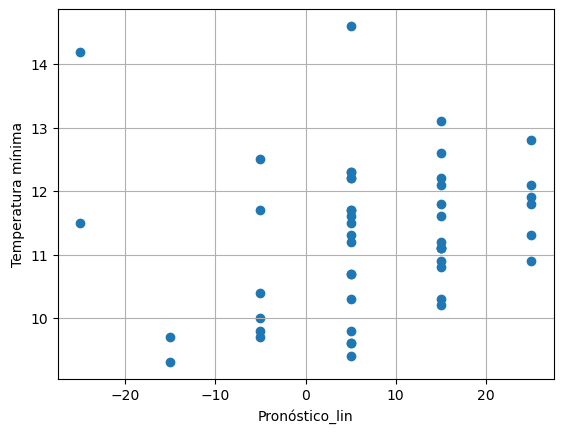

In [40]:
plt.scatter(df['Pronóstico_lin'],df['Temperatura mínima'])
plt.xlabel('Pronóstico_lin')
plt.ylabel('Temperatura mínima')
plt.grid()

In [41]:
Pronóstico_cuad

{'Soleado': np.float64(-13.333333333333334),
 'Mayormente soleado': np.float64(2.666666666666666),
 'Parcialmente nublado': np.float64(10.666666666666666),
 'Mayormente nublado': np.float64(10.666666666666666),
 'Nublado': np.float64(2.666666666666666),
 'Lluvioso': np.float64(-13.333333333333334)}

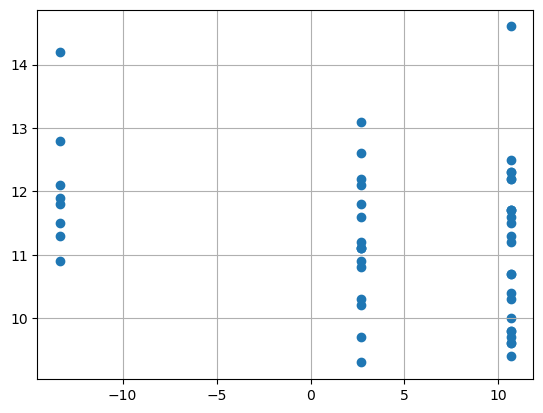

In [42]:
plt.scatter(df['Pronóstico_cuad'],df['Temperatura mínima'])
plt.grid()

In [43]:
df['Pronóstico_cuad']

0     10.666667
1     10.666667
2     10.666667
3      2.666667
4      2.666667
5      2.666667
6      2.666667
7      2.666667
8     10.666667
9      2.666667
10     2.666667
11    10.666667
12     2.666667
13     2.666667
14   -13.333333
15    10.666667
16     2.666667
17   -13.333333
18    10.666667
19    10.666667
20    10.666667
21    10.666667
22    10.666667
23    10.666667
24    10.666667
25    10.666667
26   -13.333333
27   -13.333333
28     2.666667
29   -13.333333
30     2.666667
31    10.666667
32    10.666667
33    10.666667
34     2.666667
35    10.666667
36     2.666667
37    10.666667
38     2.666667
39    10.666667
40    10.666667
41     2.666667
42    10.666667
43    10.666667
44   -13.333333
45   -13.333333
46   -13.333333
47    10.666667
Name: Pronóstico_cuad, dtype: float64

In [44]:
lin=LinearRegression()
lin.fit(df[['Pronóstico_lin','Pronóstico_cuad']],df['Temperatura mínima'])

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [45]:
f=lin.predict(df[['Pronóstico_lin','Pronóstico_cuad']])
f

array([11.05225496, 11.05225496, 10.99426739, 11.39303969, 11.39303969,
       11.39303969, 11.39303969, 11.39303969, 11.05225496, 11.39303969,
       11.39303969, 11.05225496, 11.39303969, 11.39303969, 12.01662157,
       11.05225496, 11.39303969, 11.7266837 , 11.05225496, 11.05225496,
       11.05225496, 10.99426739, 11.05225496, 10.99426739, 11.05225496,
       11.05225496, 12.01662157, 12.01662157, 11.39303969, 12.01662157,
       11.39303969, 11.05225496, 11.05225496, 11.05225496, 11.39303969,
       11.05225496, 11.39303969, 11.05225496, 11.21907697, 10.99426739,
       10.99426739, 11.21907697, 10.99426739, 11.05225496, 11.7266837 ,
       12.01662157, 12.01662157, 11.05225496])

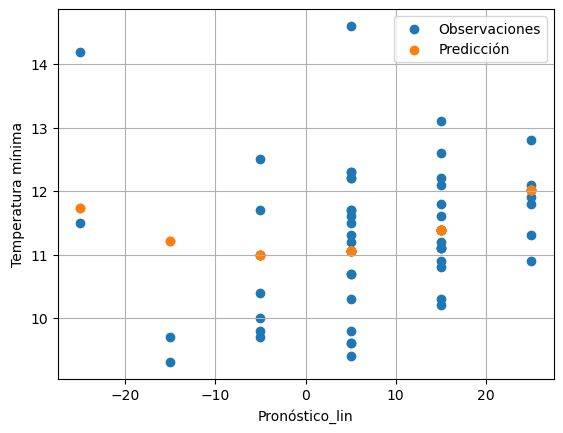

In [46]:
f=lin.predict(df[['Pronóstico_lin','Pronóstico_cuad']])
plt.scatter(df['Pronóstico_lin'],df['Temperatura mínima'],label='Observaciones')
plt.scatter(df['Pronóstico_lin'],f,label='Predicción')
plt.xlabel('Pronóstico_lin')
plt.ylabel('Temperatura mínima')
plt.legend()
plt.grid()

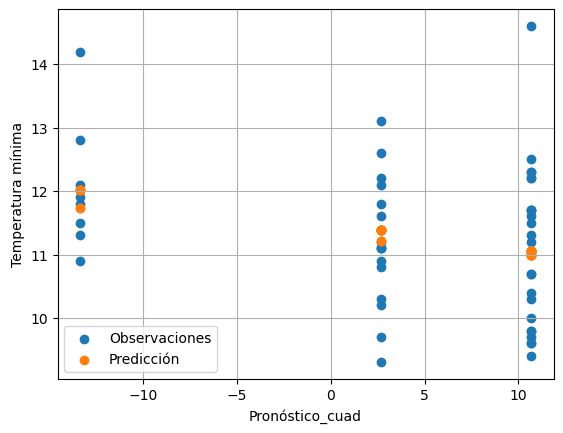

In [47]:
plt.scatter(df['Pronóstico_cuad'],df['Temperatura mínima'],label='Observaciones')
plt.scatter(df['Pronóstico_cuad'],f,label='Predicción')
plt.legend()
plt.xlabel('Pronóstico_cuad')
plt.ylabel('Temperatura mínima')
plt.grid()

### Asignación creciente

Desplazar toda la secuencia por una constante cambia los valores numéricos, pero conserva el orden. El desplazamiento por sí solo no añade información ni mejora la codificación.

escogiendo $$ X={0,1,2,3,...} $$

In [48]:
n=len(df['Días'].unique())
lim=n-1 if n%2==0 else (n-1)//2
step = 2 if n%2==0 else 1
x=range(-lim,lim+1,step)
x_list = list(x)
x_list = [x_list[i]+3 for i in range(len(x_list))]
x_list

[0, 1, 2, 3, 4, 5, 6]

In [49]:
catego=df['Días'].unique()
catego

array(['Sábado', 'Domingo', 'Lunes', 'Martes', 'Miércoles', 'Jueves',
       'Viernes'], dtype=object)

In [50]:
Días_ord=np.concatenate([catego[2:],catego[:2]])
Días_ord

array(['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado',
       'Domingo'], dtype=object)

In [51]:
a0=0
a1=5 #-0.1
Días_crec={categorías:a1*i+a0 for categorías,i in zip(Días_ord,x_list)}
Días_crec

{'Lunes': 0,
 'Martes': 5,
 'Miércoles': 10,
 'Jueves': 15,
 'Viernes': 20,
 'Sábado': 25,
 'Domingo': 30}

In [54]:
df['Días_creciente_lineal']=df['Días'].map(Días_crec)

In [55]:
df

,Días,Pronóstico,Temperatura máxima,Temperatura mínima,Días_lin,Pronóstico_lin,Pronóstico_cuad,Días_cuad,Días_creciente_lineal
0,Sábado,Parcialmente nublado,28.2,11.2,10,5,10.666667,0.0,25
1,Domingo,Parcialmente nublado,29.1,10.7,15,5,10.666667,5.0,30
2,Lunes,Mayormente nublado,26.1,10.4,-15,-5,10.666667,5.0,0
3,Martes,Mayormente soleado,29.4,11.1,-10,15,2.666667,0.0,5
4,Miércoles,Mayormente soleado,29.8,11.1,-5,15,2.666667,-3.0,10
5,Jueves,Mayormente soleado,30.2,10.2,0,15,2.666667,-4.0,15
6,Viernes,Mayormente soleado,29.3,10.3,5,15,2.666667,-3.0,20
7,Sábado,Mayormente soleado,28.6,10.9,10,15,2.666667,0.0,25
8,Domingo,Parcialmente nublado,29.0,9.8,15,5,10.666667,5.0,30
9,Lunes,Mayormente soleado,27.2,11.2,-15,15,2.666667,5.0,0


### Concava con a2 positivo

$$n*a0+\sum(a1*x+a2*x**2)=0$$

In [56]:
a2=1
a1=0
a0=-a2/n*np.sum([i**2 for i in x])
Pronóstico_cuad_con={categorías:a0+a1*i+a2*i**2 for categorías,i in zip(Pronóstico_ord,x)}
Pronóstico_cuad_con

{'Soleado': np.float64(5.0),
 'Mayormente soleado': np.float64(0.0),
 'Parcialmente nublado': np.float64(-3.0),
 'Mayormente nublado': np.float64(-4.0),
 'Nublado': np.float64(-3.0),
 'Lluvioso': np.float64(0.0)}

## Guía rápida para elegir una codificación

| Método | Representación | Qué patrón expresa | Supuesto o precaución |
|---|---|---|---|
| Ordinal simple | Un entero por nivel (`1, 2, ..., K`) | Conserva el orden de las categorías | En muchos modelos, las diferencias entre enteros se interpretan como distancias |
| Contraste lineal | Una puntuación centrada por nivel | Tendencia creciente o decreciente | El orden y la dirección deben definirse antes de codificar |
| Contraste cuadrático | Una segunda columna construida con $x^2$ | Curvatura entre niveles | No impone por sí solo que la respuesta suba o baje de forma monótona |
| Puntuación creciente | Transformación afín `a0 + a1*x`, con `a1 > 0` | Mantiene el orden ascendente | Cambiar origen o escala cambia los coeficientes, no el orden |
| Puntuación cóncava/convexa | Polinomio con término `a2*x^2` | Curvatura hacia abajo (`a2 < 0`) o arriba (`a2 > 0`) | La forma debe justificarse con el problema, no se deduce del orden solamente |

**Importante:** los contrastes polinomiales son útiles cuando el orden tiene sentido y se desea resumir una tendencia. Si no se quiere imponer una forma concreta, una codificación indicadora permite estimar un efecto distinto para cada nivel.

## Práctica de Laboratorio: Niveles de habitaciones en Melbourne

Usaremos `Data/melb_data.csv`. La variable original `Rooms` es un conteo numérico; para practicar codificación ordinal, la agruparemos en niveles ordenados: `1-2`, `3-4` y `5+` habitaciones.

1. Revisa cuántas observaciones hay en cada nivel y el precio mediano asociado.
2. Asigna códigos ordinales `1`, `2` y `3` en el orden definido.
3. Compara el número de columnas de la codificación ordinal y one-hot.
4. ¿Qué supuesto de distancia hace un modelo lineal cuando usa los códigos 1, 2 y 3?
5. Compara esa interpretación con one-hot, que permite un efecto independiente por nivel.


In [ ]:
df = pd.read_csv('Data/melb_data.csv')
df